# Scientific Python
## Central European University

## 06 NetworkX, scipy.stats, scikit-learn

Instructor: Márton Pósfai

Email: posfaim@ceu.edu

*Don't forget:* use the Slack channel for discussion, to ask questions, or to show solutions to exercises that are different from the ones provided in the notebook. [Slack channel](http://www.personal.ceu.edu/staff/Marton_Posfai/slack_forward.html)

## Why networks?

[Video.](https://ceu.cloud.panopto.eu/Panopto/Pages/Viewer.aspx?id=ac312efb-47bc-4a31-ae65-accc00922451)

A network is a set of nodes connected by a set of links. Many complex systems can be represented as networks:

<img src="http://posfaim.web.elte.hu/example_nets.png" alt="networks" style="width:75%;">

moleculas in a cell, critical infrastructure, organizations,...

[Index of Complex Networks](https://icon.colorado.edu/): A repository containing more than 5000 networks from various sources.

## Network science:
* Networks = common language to describe some aspects of these systems
* What is their structure? Why? What are the consequences of the structure?
* Very different systems, but some common properties


[ref1](https://www.nature.com/articles/nature24056), [ref2](https://www.facebook.com/notes/facebook-engineering/visualizing-friendships/469716398919), [ref3](https://ieeexplore.ieee.org/abstract/document/6065003)

## Networks

Networks/graphs are (1) a set of objects (called nodes or vertices), (2) relationships between those objects (called links or edges)

<img src="http://posfaim.web.elte.hu/networkdef.png" alt="a Network" width="66%">


You would like to know more: [book (free online)](http://networksciencebook.com), [book](https://oxford.universitypressscholarship.com/view/10.1093/acprof:oso/9780199206650.001.0001/acprof-9780199206650), [book (free online)](https://www.cs.cornell.edu/home/kleinber/networks-book/), or [course at CEU](https://courses.ceu.edu/courses/2020-2021/fundamental-ideas-network-science).

## Network analysis with python

[Video.](https://ceu.cloud.panopto.eu/Panopto/Pages/Viewer.aspx?id=27636800-3e0d-4186-a7ea-accc0095e4ef)

* [NetworkX](https://networkx.org/):
    * Implemented in python -> very portable, but slow
    * Developped by a large team, wide coverage
* [igraph](https://igraph.org/):
    * Implemented in C -> faster than NetworkX;
    * Has interface in python, R, C, and Mathematica
    * Developped by a small group
* [graph-tool](https://graph-tool.skewed.de/):
    * Implemented in C + multicore support -> fastest
    * Strong Bayesian community detection methods + nice visualization
    * Not for Windows
    * Developped by CEU's very own [Tiago Peixoto](https://networkdatascience.ceu.edu/people/tiago-peixoto)
* and others

Possible to use interchangably, for example, igraph has tools to convert to and from NetworkX and graph-tool

## 01 NetworkX

[NetworkX](http://networkx.github.io/) is a very thorough and very mature network science module for python. It's implemented in python, so it is not the fastest code on the planet, but it's very well documented, fairly easy to use.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
import networkx as nx

## The `Graph` object

[Video.](https://ceu.cloud.panopto.eu/Panopto/Pages/Viewer.aspx?id=6054416c-796d-4235-9dd4-accc009b3ff6)

The central object of NetworkX is the `Graph` which represents your network. (And its directed version the `DiGraph`.) Since it is implemented in python, `Graph` is derived from python data types: we will see that it is a combination of dictionaries (and modified dictionaries) and lists together with methods to manipulate and navigate the network.

Let's create an empty graph:

In [3]:
G = nx.Graph()
print(G.nodes, G.edges)
type(G)

[] []


networkx.classes.graph.Graph

We can add a one node at a time using the `add_node` method:

In [5]:
G.add_node(0)
print(G.nodes)

[0]


where the argument is the label of the new node, in this case `0`.

We can also add a list of new nodes at the same time using `add_nodes_from`:

In [6]:
G.add_nodes_from([2,'A','also a node',(1,2)])    # add a list of nodes
print(G.nodes)
print('number of nodes in the graph:', G.number_of_nodes())

[0, 2, 'A', 'also a node', (1, 2)]
number of nodes in the graph: 5


Note that node labels don't have to be integers, anything that can be a key of a dictionary can also be used as a node label.

Now we have bunch of disconnected nodes, let's add some edges too! Adding a single edge:

In [7]:
G.add_edge(2,'A')
print(G.nodes)
print(G.edges)

[0, 2, 'A', 'also a node', (1, 2)]
[(2, 'A')]


Or a list of edges:

In [8]:
G.add_edges_from([(0,2), ('A','also a node'),(1,3)])
print(G.nodes)
print(G.edges)

[0, 2, 'A', 'also a node', (1, 2), 1, 3]
[(0, 2), (2, 'A'), ('A', 'also a node'), (1, 3)]


Among the new edges we added `(1,3)`; however, node `3` previously didn't exist in `G`. In this case, a new node with the missing label is created automatically.

What happens if we add an already existing edge?

In [ ]:
print(G.number_of_edges())
G.add_edge(0,2)
G.add_edge(2,0)
print(G.number_of_edges())

No change, parallel edges are not allowed. (There is a separate object called `MultiGraph` that is able to represent such multiedges.)

We can create directed graps using the `DiGraph` object:

In [ ]:
DG = nx.DiGraph()
DG.add_nodes_from([0,1,2])
DG.add_edges_from([(0,1), (1,2)])
print(DG.nodes())
print(DG.edges())

In directed graphs edges have directions; therefore edge `(0,1)` (pointing from node `0` to node `1`) is not the same as edge `(1,0)` (pointing from node `1` to node `0`):

In [ ]:
DG.add_edge(1,0)
print(DG.edges())

### Exercise

Build an undirected network based on the following neighbor lists, i.e., a dictionary that has node labels as keys and corresponding value is the lists of the neighbors of the node.

<details><summary><u>Hint.</u></summary>
<p>

Use nested `for` loops to first iterate over the dictionary, then the lists inside the dictionary.
    
</p>
</details>

In [ ]:
adj_dict = {'a':['b','c'],'b':['d','a'],'c':['a'],'d':['b']}



<details><summary><u>Solution.</u></summary>
<p>


```python
G = nx.Graph()
for node1,neighbors in adj_dict.items():
    for node2 in neighbors:
        G.add_edge(node1,node2)
print(G.nodes,G.edges)
```

    
</p>
</details>


### Node and edge attributes

[Video.](https://ceu.cloud.panopto.eu/Panopto/Pages/Viewer.aspx?id=e92e14fa-d016-42b3-a856-accc009fb60b)

Both nodes and edges can have attributes that can be any data type.

We can specify the attributes when we add the nodes:

In [9]:
G = nx.Graph()
G.add_node('A',name='Adam')
G.add_nodes_from([('B',{'name':'Eve','from_rib':True}),('C',{'name':'Cain'})]) #list of tuples: (label,dict containing attributes)
print(G.nodes.data())

[('A', {'name': 'Adam'}), ('B', {'name': 'Eve', 'from_rib': True}), ('C', {'name': 'Cain'})]


We access the attributes of existing nodes as kind of a dictionary-of-dictionaries:

In [10]:
print('Dictionary of attributes of node A:',G.nodes['A'])
print('Value of attribute name:',G.nodes['A']['name'])

Dictionary of attributes of node A: {'name': 'Adam'}
Value of attribute name: Adam


We can also change and add new attributes using the attribute dictionary:

In [11]:
G.add_node('D')
print(G.nodes['D'])
G.nodes['D']['name']='Abel'
G.nodes['D']['alive']=True
print(G.nodes['D'])
G.nodes['D']['alive']=False
print(G.nodes['D'])

{}
{'name': 'Abel', 'alive': True}
{'name': 'Abel', 'alive': False}


And we can do the same thing with edges:

In [12]:
G.add_edge('A','B',weight=2.,relationship='dating')
G.add_edges_from([('A','C',{'weight': 0.5}),('A','D',{'weight': 1.5}),('C','D',{'weight': 0.01})])
print(G.edges.data())

[('A', 'B', {'weight': 2.0, 'relationship': 'dating'}), ('A', 'C', {'weight': 0.5}), ('A', 'D', {'weight': 1.5}), ('C', 'D', {'weight': 0.01})]


Edges are stored in a dictionary-of-dictionaries-of-dictionaries-like structure. Accessing and changing attributes of edges:

In [8]:
print('Dictionary contianing the neighbors of A:\n', G['A'])
print()
print('Dictionary containing the attributes of the edge A-C:\n',G['A']['C'])
print()
print('Value of weight:',G['A']['C']['weight'])
G['A']['C']['weight']=1e-5
print('Changed value:',G['A']['C']['weight'])

Dictionary contianing the neighbors of A:
 {'B': {'weight': 2.0, 'relationship': 'dating'}, 'C': {'weight': 0.5}, 'D': {'weight': 1.5}}

Dictionary containing the attributes of the edge A-C:
 {'weight': 0.5}

Value of weight: 0.5
Changed value: 1e-05


### Exercise
Create a network `numsG` where nodes are numbers  from 1 to 10 and there is a link between two nodes if one is divisable by the other, e.g. 5 and 3 are not connected, but 6 and 3 are. Add a link attribute 'res' equal to the result of the division, e.g. for the link (6-3) `res` is equal to 2. 

<details><summary><u>Hint.</u></summary>
<p>

Test if two numbers are divisible with `i%j==0`.
    
</p>
</details>

<details><summary><u>Solution.</u></summary>
<p>


```python
numsG = nx.Graph()
numsG.add_nodes_from(range(1,11))
for i in range(1,11):
    for j in range(1,i): 
        if i % j==0: # i is always larger than j
            numsG.add_edge(i,j,res=j/i)
print('node:',numsG.nodes)
print('links:',numsG.edges.data())
```

    
</p>
</details>


Now we are ready to build our own networks! However, in many cases we load networks from files that have been previously prepared by us or someone else.

## Loading networks from files

[Video.](https://ceu.cloud.panopto.eu/Panopto/Pages/Viewer.aspx?id=7ab8e49e-fbb5-409c-b2fb-accc00a44fb6)

There is an array of file formats that store network data (including formats that follow JSON and XML standards), and many of them are [handled](https://networkx.org/documentation/stable/reference/readwrite/index.html) by NetworkX. You can find network data to explore in online repositories [here](https://icon.colorado.edu), [here](https://snap.stanford.edu/data/), [here](http://konect.cc/), and [here](https://networks.skewed.de/), to list a few. We will load two networks using two different formats, and we will use these networks as examples through out the notebook.

### Edge list -- Les Misréable

Probably the most simple network file format is an edge list stored in a csv file: each line represents an edge and has minimum two columns containing the two nodes that the edge connects. Additional columns may be used for edge attributes.

For example, `lesmis.csv` conatains a network of the characters Victor Hugo's Les Misérables, where an edge (A-B) represents that characters A and B appeared in the same scene. The third column is an integer link weight that counts the number of coappearances.

When loading the file we have to specify the data type of the node labels and the edge attribute names and data types:

In [14]:
lesmisG = nx.read_edgelist("lesmis.csv", delimiter=',',nodetype=str, data=(("weight", int),))

In [15]:
lesmisG.nodes

NodeView(('Myriel', 'Napoleon', 'MlleBaptistine', 'MmeMagloire', 'CountessDeLo', 'Geborand', 'Champtercier', 'Cravatte', 'Count', 'OldMan', 'Valjean', 'Labarre', 'Marguerite', 'MmeDeR', 'Isabeau', 'Gervais', 'Fantine', 'MmeThenardier', 'Thenardier', 'Cosette', 'Javert', 'Fauchelevent', 'Bamatabois', 'Simplice', 'Scaufflaire', 'Woman1', 'Judge', 'Champmathieu', 'Brevet', 'Chenildieu', 'Cochepaille', 'Woman2', 'MotherInnocent', 'Gavroche', 'Gillenormand', 'MlleGillenormand', 'Marius', 'Enjolras', 'Bossuet', 'Gueulemer', 'Babet', 'Claquesous', 'Montparnasse', 'Toussaint', 'Tholomyes', 'Listolier', 'Fameuil', 'Blacheville', 'Favourite', 'Dahlia', 'Zephine', 'Perpetue', 'Eponine', 'Anzelma', 'Magnon', 'Pontmercy', 'Boulatruelle', 'Brujon', 'LtGillenormand', 'Gribier', 'MmePontmercy', 'Mabeuf', 'Courfeyrac', 'Jondrette', 'MmeBurgon', 'Combeferre', 'Prouvaire', 'Feuilly', 'Bahorel', 'Joly', 'Grantaire', 'Child1', 'Child2', 'MmeHucheloup', 'BaronessT', 'MlleVaubois', 'MotherPlutarch'))

The number of nodes and edges in the network:

In [ ]:
lesmisG.number_of_nodes(),lesmisG.number_of_edges()

### GraphML -- Network science coauthorship

The next network is stored in a [GraphML](https://en.wikipedia.org/wiki/GraphML) file which is an XML based file format. GraphML is a more complete format than an edge list, it can represent node, edge, and network level attributes, and also allows us to specify their the attribute data types.

The file `netscience.xml` contains the coauthorship network of network scientists from 2006: each node is a researcher and two researchers are connected if they co-authored at least one paper together. Since the file itself specifies the attribute data types, loading the network is simple: 

In [16]:
nsG = nx.read_graphml("netscience.xml")

The number of nodes and edges in the network:

In [17]:
nsG.number_of_nodes(),nsG.number_of_edges()

(1589, 2742)

In [18]:
list(nsG.nodes)[:10]

['n0', 'n1', 'n2', 'n3', 'n4', 'n5', 'n6', 'n7', 'n8', 'n9']

The nodes are labeled `n0`,`n1`,..., and have attributes:

In [19]:
nsG.nodes['n0']

{'x': 14.267913886567893, 'y': -7.002789914485814, 'name': 'ABRAMSON, G'}

where `name` is the name of the researcher, `x` and `y` are coordinates that we can use to visualize the network (more on this soon).

## Iterating over nodes and edges

[Video.](https://ceu.cloud.panopto.eu/Panopto/Pages/Viewer.aspx?id=e840ceb7-57a8-410d-a541-accc00a82e00)

Nodes and edges can be iterated over with `G.nodes()` and `G.edges()` respectively.

In [ ]:
for node in G.nodes():
    print(node)

In [20]:
for node, data in G.nodes(data=True): # data=True includes node attributes as dictionaries
    print(node, data) 

A {'name': 'Adam'}
B {'name': 'Eve', 'from_rib': True}
C {'name': 'Cain'}
D {'name': 'Abel', 'alive': False}


In [ ]:
for n1, n2, data in G.edges(data=True):
    print(n1, "<-->", n2, data)

## Degree

[Video.](https://ceu.cloud.panopto.eu/Panopto/Pages/Viewer.aspx?id=97c1370a-b535-438d-981b-accc00aa12e2)

Now that we have our networks, how can we characterize their structure? This class we are focusing mostly on properties of nodes, next class we will discuss community detection, a macroscopic feature of networks.

The most simple porperty of node is its degree, the number of neighbors it has. We can calculate it for a single node:

In [21]:
G.degree('A')

3

Or for all nodes:

In [22]:
degs = G.degree()
print(type(degs))
degs

<class 'networkx.classes.reportviews.DegreeView'>


DegreeView({'A': 3, 'B': 1, 'C': 2, 'D': 2})

This returns a `DegreeView` object which kind of modified a dictionary: you can access its elements as a dictionary, but you iterate over it as if you would iterate over the `items()` method of a dictionary.

In [23]:
print(degs['A'])
for node, deg in degs:
    print(node,deg)

3
A 3
B 1
C 2
D 2


You can also convert it to a dictionary to work with something more familiar:

In [24]:
degs=dict(degs)
print(degs,type(degs))
for node in degs:
    print(node,degs[node])
for node, deg in degs.items():
    print(node,deg)

{'A': 3, 'B': 1, 'C': 2, 'D': 2} <class 'dict'>
A 3
B 1
C 2
D 2
A 3
B 1
C 2
D 2


The Les Misérable network is weighted, you can also calculate a weighted degree of a node which is simply the sum of the weights that end at the node. For this you have to specify the name of the edge attribute that contains the weight.

In [25]:
lesmisG.degree('Valjean',weight='weight')

158

### Exercise

Calculate the average unweighted degree of the Les Misérable and the coauthorship network.


<details><summary><u>Hint.</u></summary>
<p>

Each link is connected to two nodes, so if we sum up the degree of all nodes, we get two times the number of edges.
</p>
</details>

<details><summary><u>Solution.</u></summary>
<p>


```python
print("Les Mis average degree:",2*len(lesmisG.edges)/len(lesmisG.nodes))
print("NetSci average degree:",2*len(nsG.edges)/len(nsG.nodes))
```

    
</p>
</details>


### Exercise
Find name of the researcher with the maximum degree in the coauthorship network.

<details><summary><u>Hint.</u></summary>
<p>

`nsG.degree()` is a `DegreeView` object, when you iterate over it you get a tuple (label, degree):
```python
for label,degree in nsG.degree():
    ...
```
You can also try to use the `max()` function with an appropraite lambda function as `key`. 

</p>
</details>

<details><summary><u>Solution.</u></summary>
<p>


```python
label,maxdeg = max(nsG.degree(), key=lambda x:x[1])
#nsG.degree() is a DegreeView when we iterate over it we get tuples (label,degree)
print(nsG.nodes[label]['name'])
```

    
</p>
</details>


## Drawing networks

[Video.](https://ceu.cloud.panopto.eu/Panopto/Pages/Viewer.aspx?id=c8129030-c63d-4173-b957-accc00aeb184)

We will learn how to draw networks, so we can illustrate whatever analysis we are preforming later in this notebook. NetworkX uses matplotlib to display the networks, so we can use all the trappings of matplotlib to finetune our plots!

Drawing a network requires two main steps:
* Generating a layout, i.e., deciding where to place each node so we get a pleasing figure.
* Drawing the nodes and edges

These two steps can be done automatically by calling the `draw_networkx` function:

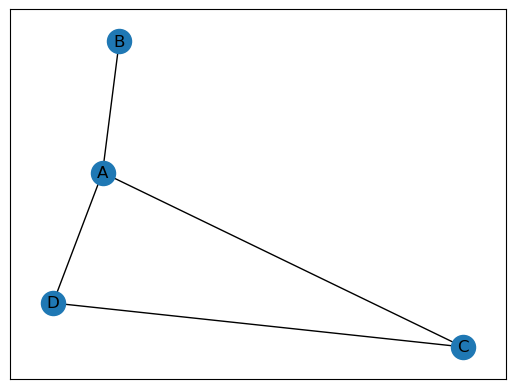

In [11]:
nx.draw_networkx(G)

The box around the network is kind of ugly, how can we remove it? Well NetworkX uses matplotlib, so we can use its functionality. However, unlike pandas' `plot` function, `draw_networkx` does not return the `Axes` object used for plotting, so we can't follow the same method as we did there. We can do two things:
* Use pyplot style functions that always operate on the current `Axes` that matplotlib keeps track of in the background
* We can use the `ax = plt.gca()` function call to get the current `Axes`, and use object oriented style functions

The following two methods produce the same output:

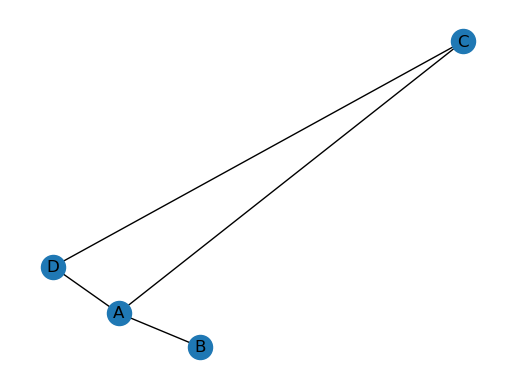

In [12]:
nx.draw_networkx(G)
#pyplot style
plt.axis('off');

#object oriented style
#ax= plt.gca()
#ax.set_axis_off();

We can get more control over our figure if we separate the steps of generating the layout and drawing nodes and edges: 

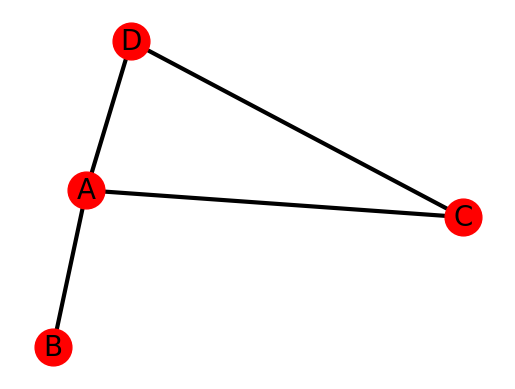

In [13]:
# layout
pos = nx.spring_layout(G) #dynamical model for node positions

# draw nodes
nx.draw_networkx_nodes(G, pos, node_size=700, node_color='red') #draw nodes
# draw edges
nx.draw_networkx_edges(G, pos, width=3) #draw edges
# draw labels
nx.draw_networkx_labels(G, pos, font_size=20) #draw labels

plt.axis('off');

The positions of the nodes are stored in the `pos` dicitionary:

In [14]:
pos

{'A': array([-0.34687238,  0.00770322]),
 'B': array([-0.46630304, -0.13175862]),
 'C': array([ 1.        , -0.01617714]),
 'D': array([-0.18682458,  0.14023253])}

You don't have to rely on NetworkX's layout algorithms to obtain a `pos` dictionary. You can calculate your own or get layout coordinates from an outside source.

Each of the attributes for drawing can be substituted by a list so the you can individually specify the properties of the nodes and edges:

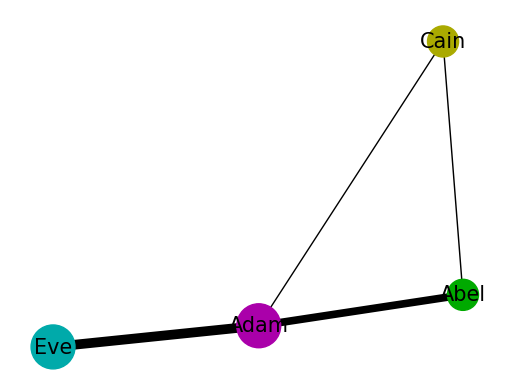

In [15]:
# layout
pos = nx.spring_layout(G) #dynamical model for node positions
# try different layouts
#pos = nx.kamada_kawai_layout(G)
#pos = nx.spectral_layout(G)
#pos = nx.circular_layout(G)
# draw nodes
nx.draw_networkx_nodes(G, pos, node_size=[1000,1000,500,500], 
                       node_color=['#aa00aa','#00aaaa',"#aaaa00","#00aa00"])
# draw edges
widths = [att['weight']*3+1 for a,b,att in G.edges(data=True)]
nx.draw_networkx_edges(G, pos, width=widths)
# draw labels
new_labels = {a:att['name'] for a,att in G.nodes(data=True)}
nx.draw_networkx_labels(G, pos, font_size=15,labels=new_labels)

plt.axis('off');

We will use color and size of nodes to represent node properties.

Note that most layout algorithms produce different results each time they are run. This is because the initialize the search for a good layout from random initial positions.

### Optional exercise

Annoyingly NetworkX doesn't add a margin automatically, so nodes near the edge o the plot can get clipped. Let's correct this! Write a function  `padding(pos,ax)` that uses matplotlibs capabilties to add a 10% padding along each side, where `pos` is the dictionary containing the positions of the nodes and `ax` is the `Axes` we are plotting on.

<details><summary><u>Hint.</u></summary>
<p>

Find the maximum and minimum value of x and y, and modify the x and y limits of plotting using `ax.set_xlim(...)` and `ax.set_ylim(...)`.

</p>
</details>

<details><summary><u>Solution.</u></summary>
<p>


```python
def padding(pos, ax):
    xs = [coord[0] for coord in pos.values()]
    ys = [coord[1] for coord in pos.values()]
    
    maxx = max(xs)
    minx = min(xs)
    maxy = max(ys)
    miny = min(ys)
    
    dx = (maxx-minx)*.1
    dy = (maxy-miny)*.1
    
    ax.set_xlim(maxx+dx,minx-dx)
    ax.set_ylim(maxy+dy,miny-dy)
    
    return
```

    
</p>
</details>


Try your solution out!

In [ ]:
pos = nx.circular_layout(G)
nx.draw_networkx_nodes(G, pos, node_size=[1000,1000,500,500], 
                       node_color=['#aa00aa','#00aaaa',"#aaaa00","#00aa00"])
widths = [att['weight']*3+1 for a,b,att in G.edges(data=True)]
nx.draw_networkx_edges(G, pos, width=widths)
labels = {a:att['name'] for a,att in G.nodes(data=True)}
nx.draw_networkx_labels(G, pos, font_size=15,labels=labels)

plt.axis('off');

padding(pos,plt.gca())

### Drawing Les Mis

[Video.](https://ceu.cloud.panopto.eu/Panopto/Pages/Viewer.aspx?id=956618b3-b618-44c7-abb0-accc00b405e7)

Let's create a plot of the Les Misérable network!

In [26]:
lesmis_pos = nx.kamada_kawai_layout(lesmisG)

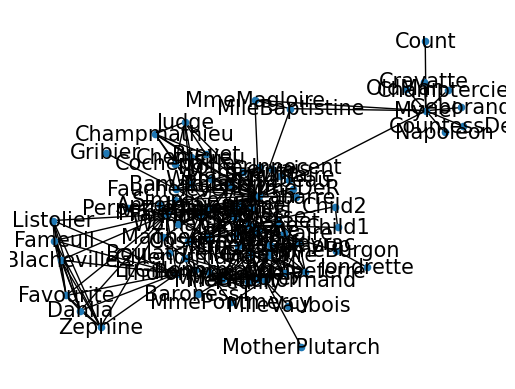

In [27]:
nx.draw_networkx_nodes(lesmisG, lesmis_pos, node_size=20)
nx.draw_networkx_edges(lesmisG, lesmis_pos)
nx.draw_networkx_labels(lesmisG, lesmis_pos, font_size=15)

plt.axis('off');

So far not so nice. Let's improve it!
* We increase the size using matplotlib
* Let's color the nodes based on how many neighbors they have
* The labels are too large and too many: let's reduce their size and only show them for nodes with degree >15

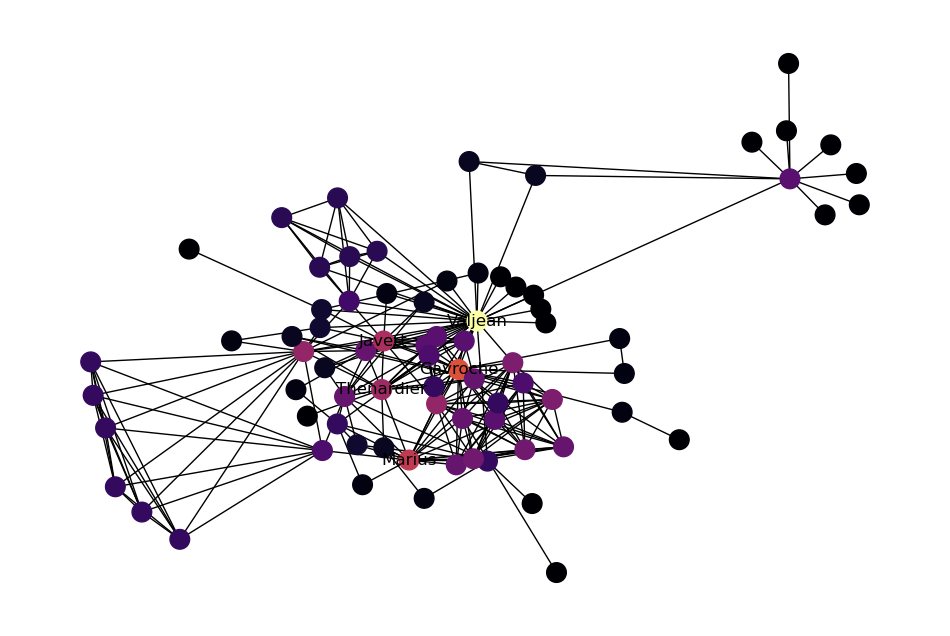

In [28]:
plt.figure(figsize=(12,8))

colors = [ lesmisG.degree(node) for node in lesmisG.nodes]
nx.draw_networkx_nodes(lesmisG, lesmis_pos, node_size=200, node_color=colors, cmap=plt.cm.inferno)
nx.draw_networkx_edges(lesmisG, lesmis_pos)

new_labels = {node:node for node in lesmisG.nodes if lesmisG.degree(node)>15}
nx.draw_networkx_labels(lesmisG, lesmis_pos, labels=new_labels, font_size=12)

plt.axis('off');

### Exercise
Further improve the plot:
* Make the node size a linear function of node degree: `size = 30*degree + 20`.
* The network is weighted, make the thickness of the edges proportional to the weight

<details><summary><u>Hint.</u></summary>
<p>

Create a list for the node sizes using
```
sizes = [ ... for node in lesmisG.nodes]
```

</p>
</details>

<details><summary><u>Solution.</u></summary>
<p>


```python
plt.figure(figsize=(12,8))

sizes = [ 30*lesmisG.degree[node]+20 for node in lesmisG.nodes]
colors = [ lesmisG.degree[node] for node in lesmisG.nodes]
nx.draw_networkx_nodes(lesmisG, lesmis_pos, node_size=sizes, node_color=colors, cmap=plt.cm.inferno)

widths = [1+.2*att['weight'] for a,b,att in lesmisG.edges(data=True)]
nx.draw_networkx_edges(lesmisG, lesmis_pos, width=widths,edge_color='#00000088')
#we also set the links to be transparent 
#the "88" at the end of the color sets the level of transparency, try changing it

labels = {node:node for node in lesmisG.nodes if lesmisG.degree[node]>15}
nx.draw_networkx_labels(lesmisG, lesmis_pos, labels=labels, font_size=12)

plt.axis('off');
```

    
</p>
</details>


### Drawing coauthorship network

[Video.](https://ceu.cloud.panopto.eu/Panopto/Pages/Viewer.aspx?id=c259d10a-f1b0-44e1-a97d-accc00b8f191)

NetworkX is not so good at finding layouts for larger networks, e.g.

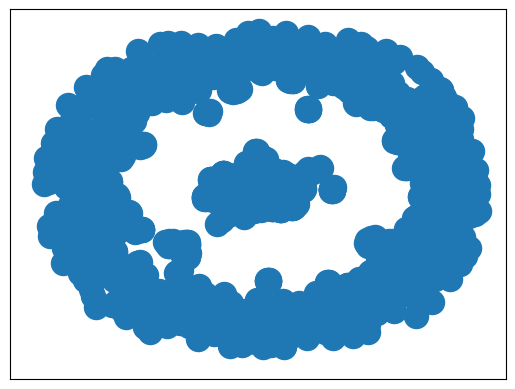

In [20]:
nx.draw_networkx(nsG, with_labels=False)

Luckily this network came with precalculated coordinates, you can find them as node properties `x` and `y`:

In [ ]:
nsG.nodes['n0']

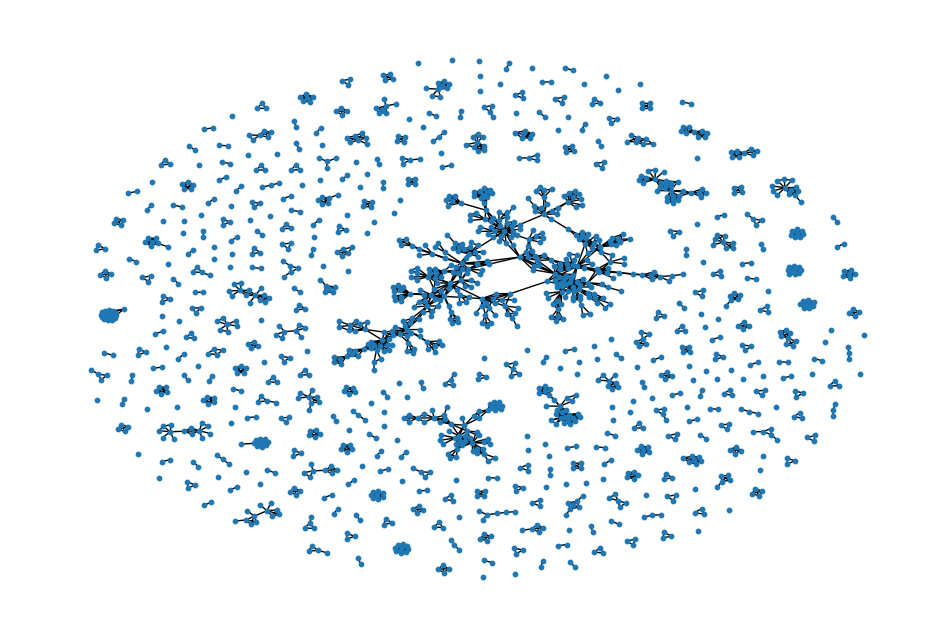

In [21]:
ns_pos = {node:[data['x'],data['y']] for node,data in nsG.nodes(data=True)}

plt.figure(figsize=(12,8))

nx.draw_networkx_nodes(nsG, ns_pos, node_size=10)
nx.draw_networkx_edges(nsG, ns_pos)


plt.axis('off');

#### Connected components

So this network is made up of a number of connected components that are separated from each other, many of them small, even containing a single author. Let's look at the largest component separately.

NetworkX can find all components:

In [22]:
comps = list(nx.connected_components(nsG)) # returns a generator (remember?) that we convert to a list
for c in comps[:10]:
    print(c)


{'n1084', 'n946', 'n0', 'n1'}
{'n3', 'n5', 'n2', 'n4', 'n6'}
{'n11', 'n7', 'n1424', 'n1425', 'n10', 'n9', 'n8', 'n1532'}
{'n13', 'n1049', 'n1047', 'n15', 'n1048', 'n12', 'n1050', 'n14'}
{'n16', 'n18', 'n17'}
{'n19'}
{'n21', 'n20', 'n22'}
{'n201', 'n25', 'n369', 'n200', 'n23', 'n202', 'n24'}
{'n26'}
{'n27', 'n28', 'n29'}


The `connected_components` function returns a generator (reminder: generators are iterable objects that do not calculate and store its elements ahead of time, but produce them on the fly as we iterate over them). You cannot index or slice generators; here we convert it to a list so we can better investigate it.

The components are sets of nodes. Sets are python objects that can contain elements only once. A list may contain the same element twice (e.g., `[1,2,2]`), while a set only contains unique elements (e.g., `{1,2}`). You can try converting a list `L` with `set(L)`.

The `len(s)` function call returns the number of elements in the set `s`. So we can select the largest component with:

In [23]:
len(comps[0])

4

In [24]:
maxcomp = max(comps,key=len)
print(len(maxcomp))

379


In [25]:
cnsG = nsG.subgraph(maxcomp)

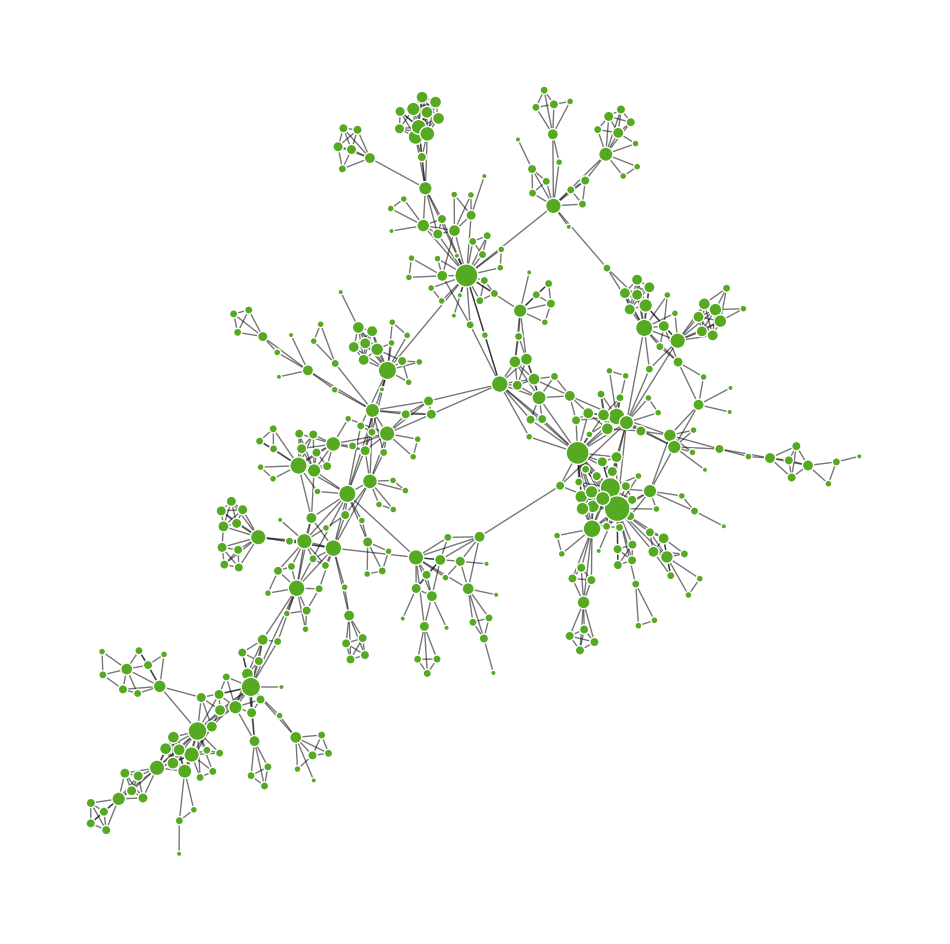

In [26]:
plt.figure(figsize=(12,12))

sizes = [ 10*cnsG.degree[node]+5 for node in cnsG.nodes]
nx.draw_networkx_nodes(cnsG, ns_pos, node_size=sizes, node_color='#55aa22', edgecolors='#ffffff')

nx.draw_networkx_edges(cnsG, ns_pos, edge_color='#00000088')

plt.axis('off');

That is more digestible.

## Node centralities

[Video.](https://ceu.cloud.panopto.eu/Panopto/Pages/Viewer.aspx?id=a8dbfd0a-c51a-43eb-8188-accc00c771db)

Centralities are a group of measures that aim to quantify the importance of the nodes of network based on network structure only. Every centrality approaches the problem from a different aspect, the right centrality to calculate depends on the question you are asking. Here we will look at three classic centralities (degree, PageRank, and betweenness) and calculate them for the example networks.


### Degree

The simplest centrality is something that we already looked at: the degree of the node itself, i.e., the number of connections a node has. The guiding idea is that the more active you are or the more connections you have, the more effect you will have on the functioning of the system.

As we already saw, the degree of the nodes can be calulated using the `degree` method of the graph object, which returns a dictionary-like object that we can use to access the degree of individual nodes or to iterate over the node labels and degrees in parallel; or we can convert it to a dictionary to work with something more familiar.

Let's calculate the degree of the nodes for the largest component of the network science collaboration network:

In [28]:
ns_deg = dict(cnsG.degree())
print("Access the degree of node n489:",ns_deg['n489'])
print()
print("Iterate over nodes and degrees:")
for node,degree in ns_deg.items():
    print(node,degree)

Access the degree of node n489: 3

Iterate over nodes and degrees:
n576 2
n268 11
n1415 4
n894 3
n265 11
n1182 1
n956 6
n562 8
n776 3
n1163 2
n1560 3
n610 2
n100 4
n343 10
n697 12
n149 4
n507 4
n774 6
n158 2
n763 4
n429 1
n127 12
n1481 2
n342 3
n370 2
n1452 1
n585 3
n1550 4
n638 6
n280 6
n977 4
n51 9
n162 5
n402 12
n474 2
n77 3
n1342 3
n1451 2
n285 6
n378 3
n501 2
n1556 3
n1414 4
n1406 6
n222 5
n224 5
n331 2
n1189 2
n48 6
n1041 3
n934 2
n893 5
n761 10
n729 2
n1315 8
n485 1
n1162 6
n1557 3
n1295 4
n1137 4
n220 6
n218 9
n327 15
n514 3
n252 7
n694 5
n328 6
n1027 1
n762 4
n759 3
n50 3
n612 3
n1215 4
n1255 3
n1408 6
n502 3
n503 2
n1416 3
n1136 4
n490 5
n692 1
n46 12
n548 3
n96 15
n986 2
n191 4
n465 2
n590 6
n653 3
n52 4
n461 3
n416 9
n128 5
n771 5
n1482 2
n652 7
n266 11
n708 4
n346 6
n99 5
n517 12
n329 5
n1039 2
n186 6
n1197 3
n701 3
n308 8
n983 3
n955 2
n121 9
n736 2
n1214 4
n1460 3
n984 7
n1561 3
n31 2
n1005 1
n788 3
n1417 3
n303 7
n575 2
n1314 4
n97 11
n500 5
n47 3
n193 3
n53 16
n561 8
n

Let's select the top 10 nodes:

In [29]:
degtop10 = sorted(ns_deg.keys(), key= lambda x:-ns_deg[x])[:10]
degtop10

['n33', 'n34', 'n78', 'n54', 'n216', 'n219', 'n281', 'n53', 'n327', 'n96']

Print out the top 10 nodes:

In [30]:
rank = 1
for node in degtop10:
    print(rank, nsG.nodes[node]['name'], ns_deg[node], sep='\t')
    rank+=1

1	BARABASI, A	34
2	JEONG, H	27
3	NEWMAN, M	27
4	OLTVAI, Z	21
5	BOCCALETTI, S	19
6	KURTHS, J	18
7	SOLE, R	17
8	VICSEK, T	16
9	LATORA, V	15
10	DIAZGUILERA, A	15


These are still all prominent researchers in network science even 15 years after the collection of this data. Two of the top three [László Barabási](https://scholar.google.com/citations?user=vsj2slIAAAAJ) and [Mark Newman](https://scholar.google.com/citations?user=rQ68pVwAAAAJ) are arguably the most influential network scientists.

Let's plot the largest component of the coauthorship network, label only the top 10 degree researchers and color them differently.

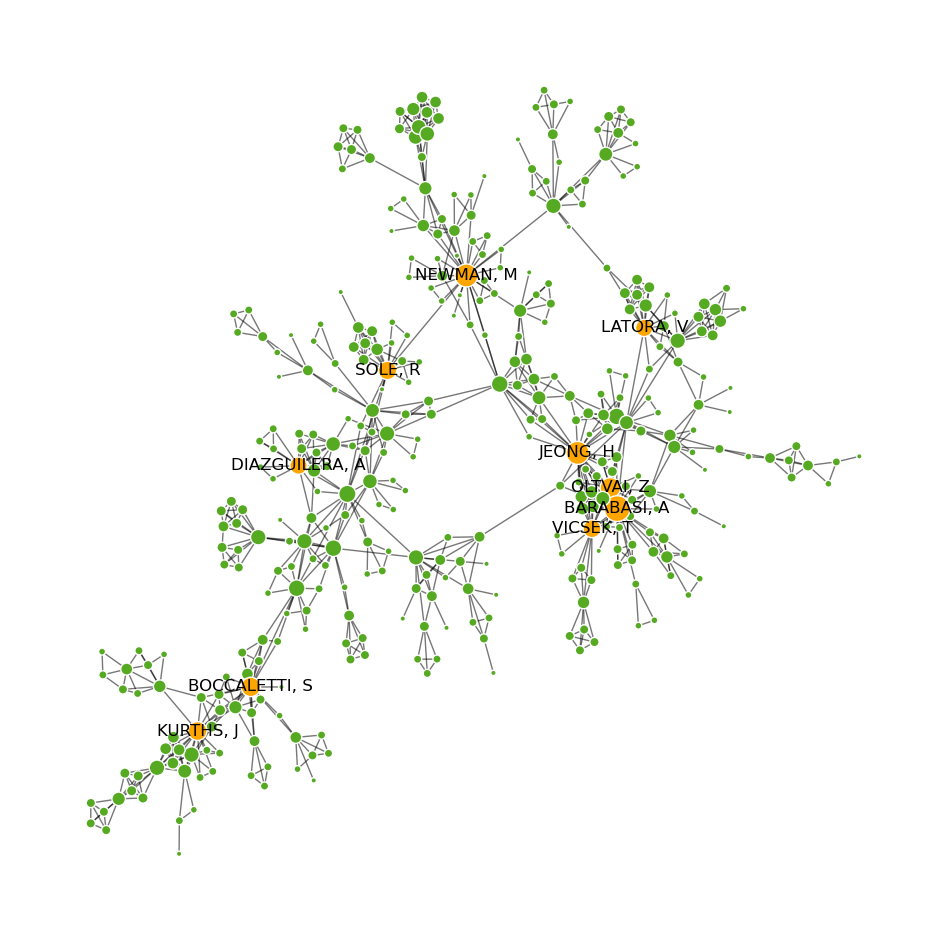

In [31]:
plt.figure(figsize=(12,12))

sizes = [ 10*cnsG.degree(node)+5 for node in cnsG.nodes]

colors = ['#ffa500' if node in degtop10 else '#55aa22' for node in cnsG.nodes]

nx.draw_networkx_nodes(cnsG, ns_pos, node_size=sizes, node_color=colors, edgecolors='#ffffff')

nx.draw_networkx_edges(cnsG, ns_pos, edge_color='#00000088')

# draw labels
new_labels = {node:cnsG.nodes[node]['name'] for node in degtop10}
nx.draw_networkx_labels(cnsG, ns_pos, labels=new_labels, font_size=12)

plt.axis('off');

What kind of pattern do we see? The top 10 nodes mostly seem to be situated by themselves at the center of locally dense clusters. They are research group leaders and leading collaborations, but largely working independent from each other. The only exception is a group with Barabási at the center: this is a cluster of three Hungarians and a former postdoc of Barabási.

The degree of a node simply counts the number of collaborators a researcher has. This is a crude approximation of their importance: not all collaborations are equal, collaborating with other high ranking researchers should increase your influence more than collaborating with lesser known scientists. How can we take this into account?

### PageRank

[Video.](https://ceu.cloud.panopto.eu/Panopto/Pages/Viewer.aspx?id=911f9cb4-7712-4da3-9058-accc00cd1942)

When developping the first version of the Google search engine Larry Page and Sergey Brin faced the problem: how should they rank the websites so that the most relevant and important sites appear first? They thought of this as a network centrality problem. They constructed a directed network representing the www, where the nodes are websites and a directed link A->B indicates that website A has a link point to website B. These links can be considered as endorsements: A finds B important enough to link to it.

Existing algorithms counted the number of links (the incoming degree of the nodes) to quantify the importance of the nodes. The innovation of Larry Page and Sergey Brin was to weight endorsement coming from more important websites higher than the ones coming from low-ranked pages, the called their algorithm [PageRank](https://en.wikipedia.org/wiki/PageRank).

The outline of the approach is the following: Imagine that you are randomly navigating the web, clicking on links randomly. The probability that at a given moment you are on website A is the PageRank value of A. What this means:
* links from important pages matter more, and
* links from pages that endorse few other pages matter more.

(There is one more twist: after a while you would always get stuck at sinks, pages that do not have outgoing links. To avoid this PageRank occasionally restarts from a random page.)



<img src='https://upload.wikimedia.org/wikipedia/en/thumb/8/8b/PageRanks-Example.jpg/800px-PageRanks-Example.jpg' width='50%'>

The early success of the search engine was due to the fact that PageRank is very good at ranking the top nodes.

Let's calculate the PageRank of the researchers in the coauthorship network and print out the top 10:

In [ ]:
ns_pr = nx.pagerank(cnsG)
type(ns_pr)

In [ ]:
prtop10 = sorted(ns_pr.keys(), key= lambda x:-ns_pr[x])[:10] # list of tuples: (label, pr)
rank = 1
for node in prtop10:
    print(rank,nsG.nodes[node]['name'],ns_pr[node], sep='\t')
    rank+=1

There is considerable overlap between the top 10 nodes based on degree, but there are some new names and the order also changed.

### Exercise

Let's plot the network again such that:
* node sizes still represent degree
* node color corresponds to PageRank value
* we only label the top 10 nodes based on PageRank

<details><summary><u>Hint.</u></summary>
<p>

To set the node color, create a list containing the PageRank values from the dictionary:
```python
prlist = [ns_pr[node] for node in cnsG.nodes]
```

</p>
</details>

<details><summary><u>Solution.</u></summary>
<p>


```python
plt.figure(figsize=(12,12))

sizes = [ 10*cnsG.degree[node]+5 for node in cnsG.nodes]

prlist = [ns_pr[node] for node in cnsG.nodes]

nx.draw_networkx_nodes(cnsG, ns_pos, node_size=sizes, node_color=prlist, edgecolors='#ffffff')

nx.draw_networkx_edges(cnsG, ns_pos, edge_color='#00000088')

# draw labels
labels = {node:cnsG.nodes[node]['name'] for node in prtop10}
nx.draw_networkx_labels(cnsG, ns_pos, labels=labels, font_size=12)

plt.axis('off');
```

    
</p>
</details>


Let's look at the relationship between degree and PageRank more systematically using a scatter plot:

In [ ]:
prlist  = [ns_pr[node] for node in cnsG.nodes]
deglist = [ns_deg[node] for node in cnsG.nodes]

plt.scatter(deglist,prlist)
plt.xlabel('degree')
plt.ylabel('PageRank');

The correlation is strong, but not perfect. There are some meaningful differences: with degree Newman was tied with Jeong, while PageRank ranks Newman higher. So which one is a better choice? Depends:
* Degree ranks researchers by count of collaborators
* PageRank interprets collaborations as endorsements

It is better to ask specific questions like: Does my centrality explain some quantity not captured directly by the network such as citations, awards, future collaborations? With well defined questions it is easier to select the right quantity.

PageRank and degree are some classic and well-known centrality measures. There is, however, a endless supply of alternatives, each aiming to capture a different aspect of the network, for a large collection [see](http://schochastics.net/sna/periodic.html). You should choose the one that makes the most sense for your data and question.

## 02 scipy.stats -- Global warming signatures on the temperature data of Stockholm

In [30]:
import datetime
import pandas as pd
import seaborn as sns

[Video.](https://ceu.cloud.panopto.eu/Panopto/Pages/Viewer.aspx?id=666087d1-17f7-47f6-af00-acd30091f0c6)

You have been pondering the question: is there global warming? You are a born sceptic so you're not ready to trust anyone except your own data analysis (and random text files that you found on the internet).

We will analyze the daily mean temperature of Stockholm available [here](https://bolin.su.se/data/stockholm-historical-temps-daily-2) using the stats and optimize submodule of [SciPy](https://docs.scipy.org/doc/scipy/reference/).

In [31]:
from scipy import optimize
from scipy import stats

 ### Loading and preparing the data
 
 Take a peek inside the data file (Windows users: open the file separately)!

In [32]:
!head stockholm_daily_mean_temperature_1756-2020.csv

date,raw,homo,adjust,site
1756-01-01,-8.7,-8.7,-8.7,1
1756-01-02,-9.2,-9.2,-9.2,1
1756-01-03,-8.6,-8.6,-8.6,1
1756-01-04,-7.7,-7.7,-7.7,1
1756-01-05,-7.2,-7.2,-7.2,1
1756-01-06,-1.6,-1.6,-1.6,1
1756-01-07,0.7,0.7,0.7,1
1756-01-08,1.3,1.3,1.3,1
1756-01-09,2.4,2.4,2.4,1


What do these columns mean? Check out the description [here](https://bolin.su.se/data/stockholm-historical-temps-daily-2). The `raw` column contains the original temperature measurements, let's work with those.

Let's use pandas to load and prepare the data for analysis.

Loading the file into dataframe:

In [33]:
temps_df = pd.read_csv("stockholm_daily_mean_temperature_1756-2020.csv")
temps_df

,date,raw,homo,adjust,site
0,1756-01-01,-8.7,-8.7,-8.7,1
1,1756-01-02,-9.2,-9.2,-9.2,1
2,1756-01-03,-8.6,-8.6,-8.6,1
3,1756-01-04,-7.7,-7.7,-7.7,1
4,1756-01-05,-7.2,-7.2,-7.2,1
...,...,...,...,...,...
96785,2020-12-27,4.2,3.5,3.5,3
96786,2020-12-28,4.1,3.4,3.4,3
96787,2020-12-29,4.4,3.7,3.7,3
96788,2020-12-30,2.5,1.8,1.8,3


There is data going back all the way to 1756. 

In [34]:
temps_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96790 entries, 0 to 96789
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   date    96790 non-null  object 
 1   raw     96790 non-null  float64
 2   homo    96790 non-null  float64
 3   adjust  96790 non-null  float64
 4   site    96790 non-null  int64  
dtypes: float64(3), int64(1), object(1)
memory usage: 3.7+ MB


The dates are currently stored in strings, that is not really useful for calculations. We should convert it to pandas' datetime object (remember from the second pandas class?):

In [35]:
temps_df['date']=pd.to_datetime(temps_df['date'], format="%Y-%m-%d")
temps_df['date']

0       1756-01-01
1       1756-01-02
2       1756-01-03
3       1756-01-04
4       1756-01-05
           ...    
96785   2020-12-27
96786   2020-12-28
96787   2020-12-29
96788   2020-12-30
96789   2020-12-31
Name: date, Length: 96790, dtype: datetime64[ns]

### Exercise

According to the data description, some of the temperatures before 1800 are unreliable. Remove dates before 1800 from the dataframe!

<details><summary><u>Hint.</u></summary>
<p>
    
You can look up pandas' `drop` function which can remove rows or columns. Or you can use filtering
```python
temps_df = temps[condition].copy()
```
The `copy()` function makes sure that the rows are actually deleted and pandas doesn't just create a new view of the data. You might get some angry warning messages from panda if you are creating a new column on a filtered view.
    
</p>
</details>

<details><summary><u>Solution.</u></summary>
<p>
    
```python
temps_df = temps_df[temps_df['date']>=datetime.datetime(1800,1,1)].copy()
temps_df #see if it worked
```
    
</p>
</details>

We are interested in long term effects, so let's look at the yearly averages so we can not worry about seasonal changes.

### Exercise

Create a pandas series where the rows are labeled by year containing the yearly averages, and plot it:
* Create a new column that conatains the year of the observation.
* Use `groupby` to calculate the yearly averages of the `raw` temperature, and store it in a pandas dataframe with two columns `year` and `raw`.
* Plot using pandas.

<details><summary><u>Hint.</u></summary>
<p>
    
To create the `year` column apply the `lambda dt:dt.year` function to the `date` column.
    
</p>
</details>

<details><summary><u>Solution.</u></summary>
<p>
    
```python
temps_df['year'] = temps_df['date'].apply(lambda dt:dt.year)
yearly_avg = temps_df.groupby('year')['raw'].mean().reset_index()

yearly_avg.plot(x='year',y='raw')
plt.ylabel('Avg. temp. [C]');
```
    
</p>
</details>

Squinting at the figure kind of suggests that there is a warming tendency, but let's try to be more precise.

### Pearson correlation coefficient

[Video.](https://ceu.cloud.panopto.eu/Panopto/Pages/Viewer.aspx?id=85d82662-b671-4f1c-9b91-acd300997ddb)

Perhaps the first thing most people would try is the Pearson correlation coefficient, as it is easy to calculate and gives a single value to characterize the strength of the relationship between two variables. 


#### Definition
Let $X$ and $Y$ be random data with variances $\sigma_X$ and $\sigma_Y$ respectively.
The population Pearson correlation coefficient is
$$ \rho_{X,Y}=\frac{\mathrm{E}[(X-\mu_X)(Y-\mu_Y)]}{\sigma_X\sigma_Y},$$
where E is the expectation value, $\mu_X$ and $\mu_Y$ are the average of $X$ and $Y$ respectively. It has a value between $[-1,1]$.

It measures the strength of a linear relationship, so nonlinear connections can produce misleading values:

<img src="https://upload.wikimedia.org/wikipedia/commons/d/d4/Correlation_examples2.svg">

scipy.stats has a function to calculate the correlation between two variables in a sample:

In [36]:
r, p = stats.pearsonr(yearly_avg['year'],yearly_avg['raw'])
print(r,p)

NameError: name 'yearly_avg' is not defined

The >0.5 correlation is an indication that there is an increasing trend.

The `pearsonr` function also returns a p-value testing the hypothesis that there is no correlation.

Side note on the p-value: Probability to obtain more extreme event than observed under the given null model.
<img src="https://upload.wikimedia.org/wikipedia/commons/3/3a/P-value_in_statistical_significance_testing.svg" width=640px>


We found a very small p-value. Should we take this seriously?

In [ ]:
?stats.pearsonr

Not an hundred percent: the statistical test assumes that that the sample comes from a bivariate normal distribution and the years are definitely not normally distributed. We could still salvage the use of Pearson correlation by doing a bootstrapping or permutation test, but instead let's move on to fitting a linear function which is more appropriate to the problem (but related to linear correlation).

### Exercise

Generate a sample of bivariate normal variables using scipy.stats' `multivariate_normal.rvs` with covariance matrix `cov=[[1,0.5],[0.5,1]` and do a Pearson correlation test. Check documentation [here](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.multivariate_normal.html).

<details><summary><u>Hint.</u></summary>
<p>
    
If you set the `size=n` as an attribute of `multivariate_normal.rvs` it returns `n` two-dimensional random variables in a NumPy array with 2 columns and `n` rows. 

To select the 0 column using slicing write `sample[:,0]`.
</p>
</details>

In [ ]:
cov=[[1,0.5],[0.5,1]]


<details><summary><u>Solution.</u></summary>
<p>
    
```python
sample = stats.multivariate_normal.rvs(cov=cov,size=100)
stats.pearsonr(sample[:,0],sample[:,1])
```
    
</p>
</details>

### Exercise

Generate 100 samples of 1000 independent normally distibuted variables, for each pair of samples test the hypothesis that they are independent using `stats.pearsonr`. How many and what fraction of all p-values are under 0.05?

<details><summary><u>Hint.</u></summary>
<p>
    
```python
samples = np.random.normal(size=(100,1000))
```
generates an array of independent normal random numbers, each row is a sample with size 1000. Use nested `for` loops to compare all sample pairs.
    
</p>
</details>

<details><summary><u>Solution.</u></summary>
<p>
    
```python
samples = np.random.normal(size=(100,1000))
ps = []
for i in range(100):
    for j in range(i+1,100):
        r,p = stats.pearsonr(samples[i],samples[j])
        ps.append(p)
        
below = [p for p in ps if p<0.05]
print(f"Number of p-values below 0.05 {len(below)}, percentage:{len(below)/len(ps):.3f}")
```
    
</p>
</details>

### Linear fit

[Video.](https://ceu.cloud.panopto.eu/Panopto/Pages/Viewer.aspx?id=2801c6ef-4f31-472f-8f81-acd3009d7b8c)

The next thing that we will try is to fit a linear function to the data. In the matplotlib class, we already used the `curve_fit` function of the scipy.optimize module, to fit a function to data via the least-squares method. Let's use it here too!

First, we need to define the test funtion:

In [ ]:
def test_lin(year, slope, intercept):
    return slope*year + intercept

The first argument of the test funtion has to be the measurement point where we are evaluating the function, and the rest are the parameters that we are fitting. It returns our prediction.

In [ ]:
linfit, params_covariance = optimize.curve_fit(test_lin, yearly_avg['year'], yearly_avg['raw'])
print(linfit, np.sqrt(np.diag(params_covariance)))

The function returns the best fit values of the parameters and their covariance matrix as numpy arrays. To get the standard error of the parameters, we take the diagonal elements of the covariance matrix using `np.diag` and take the elementwise square root using `np.sqrt`.

How to interpret this result? The slope is approximately 0.01 meaning that there is 0.1 &deg;C increase every decade. The slope is one order of magnitude larger than the standard error.

We can also compare the slope to what we would get for random data drawn from a normal distribution with the average and standard deviation equal to the average and standard deviation of the yearly data:

In [ ]:
avg = yearly_avg['raw'].mean()
std = yearly_avg['raw'].std()
for i in range(10):
    linfit, params_covariance = \
        optimize.curve_fit(test_lin, yearly_avg['year'], np.random.normal(avg,std,size=len(yearly_avg)))
    print(linfit, np.sqrt(np.diag(params_covariance)))

The slopes found for the random data are orders of magnitude smaller than the real fit, and they are comparable to the estimated standard error.

Of course what we did is simple linear regression, and stats has a dedicated function for it which also tests the hypothesis that the slope is zero. (`curve_fit` is more useful for fitting nonlinear functions.)

In [ ]:
result_yearly = stats.linregress(yearly_avg['year'], yearly_avg['raw'])
result_yearly

Access parts of the result:

In [ ]:
result_yearly.slope

The p-value is very small, so we can safely conculde that the data does not come from random fluctuations (the slope is not zero).

### Exercise

Plot the yearly average data with the linear regression line.

<details><summary><u>Hint.</u></summary>
<p>
    
Plot the `raw` temps using pandas as we did before. Include the linear regression using matplotlib's `plot` where the x data can be  `yearly_avg['year']`.
    
</p>
</details>

<details><summary><u>Solution.</u></summary>
<p>
    
```python
yearly_avg.plot(x='year',y='raw',linewidth=.5)
plt.ylabel('Avg. temp. [C]')
plt.plot(yearly_avg['year'], result_yearly.slope*yearly_avg['year']+result_yearly.intercept,
         '--', linewidth=2.,label='Lin. fit')
plt.legend();
```
    
</p>
</details>

## Deseasoning

[Video.](https://ceu.cloud.panopto.eu/Panopto/Pages/Viewer.aspx?id=9302614e-1f04-48b4-8029-acd300afe570)

We looked at the yearly averages so that we don't have to care about the seasonal changes. Another way to deal with the fact that in Stockholm summer is warmer than winter is to deseason the data: for each day of the year subtract the long-term average of that day, for example, the average of Jan 5 over many years.

First, let's create an average temperature profile for every day of the year. How should we do this? We could number the days of the year from 0 to 364, but there is the pesky February 29. Let's create a new column called that contains a tuple with the month and day of month, e.g., Jan 5 should be `(1,5)`. 

In [37]:
temps_df['day_of_year'] = temps_df['date'].apply(lambda dt:(dt.month,dt.day))
temps_df

,date,raw,homo,adjust,site,day_of_year
0,1756-01-01,-8.7,-8.7,-8.7,1,"(1, 1)"
1,1756-01-02,-9.2,-9.2,-9.2,1,"(1, 2)"
2,1756-01-03,-8.6,-8.6,-8.6,1,"(1, 3)"
3,1756-01-04,-7.7,-7.7,-7.7,1,"(1, 4)"
4,1756-01-05,-7.2,-7.2,-7.2,1,"(1, 5)"
...,...,...,...,...,...,...
96785,2020-12-27,4.2,3.5,3.5,3,"(12, 27)"
96786,2020-12-28,4.1,3.4,3.4,3,"(12, 28)"
96787,2020-12-29,4.4,3.7,3.7,3,"(12, 29)"
96788,2020-12-30,2.5,1.8,1.8,3,"(12, 30)"


Now we can use `groupby` to get the average temps for all days of the year

In [38]:
doy_avg=temps_df.groupby('day_of_year')['raw'].mean()
doy_avg

day_of_year
(1, 1)     -3.259623
(1, 2)     -3.246415
(1, 3)     -3.361509
(1, 4)     -3.543396
(1, 5)     -3.676981
              ...   
(12, 27)   -2.406038
(12, 28)   -2.383396
(12, 29)   -2.307170
(12, 30)   -2.799245
(12, 31)   -3.163774
Name: raw, Length: 366, dtype: float64

What we have is a pandas series where the rows are labeled by the day-of-year tuples. Let's plot the profile:

AttributeError: 'DataFrame' object has no attribute 'year'

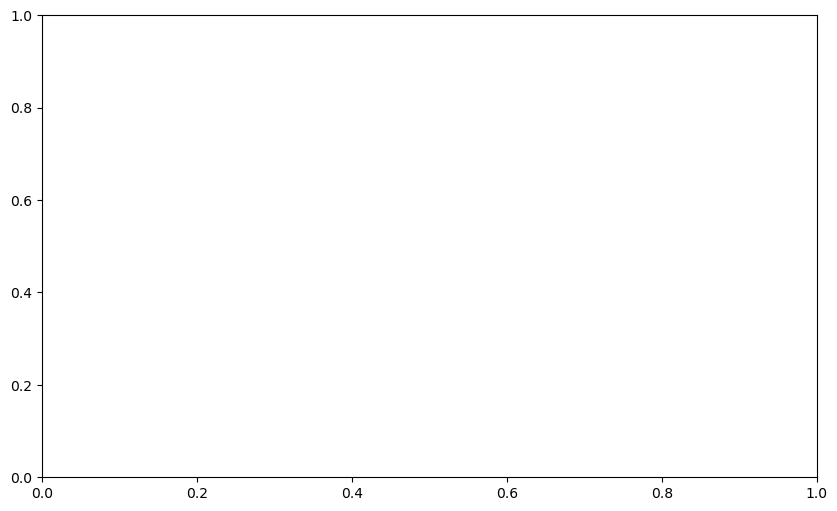

In [39]:
fig,ax= plt.subplots(figsize=(10,6))

#plot every tenth year to illustrate fluctuations
for year in range(1800,2021,10):
    temps_df[temps_df.year==year].plot(x='day_of_year',y='raw',alpha=.15,ax=ax,label='')

doy_avg.plot(ax=ax,color='r',label='average',linewidth=3)

plt.xlabel('day of year')
plt.ylabel('temp [°C]');
plt.legend()
plt.title('Yearly temperature profile');

Now we can create a new column in `temps_df` containing the deseasoned temperatures:

In [40]:
temps_df['deseasoned']=temps_df.apply(lambda row: row['raw']-doy_avg[row['day_of_year']],axis=1)
temps_df

,date,raw,homo,adjust,site,day_of_year,deseasoned
0,1756-01-01,-8.7,-8.7,-8.7,1,"(1, 1)",-5.440377
1,1756-01-02,-9.2,-9.2,-9.2,1,"(1, 2)",-5.953585
2,1756-01-03,-8.6,-8.6,-8.6,1,"(1, 3)",-5.238491
3,1756-01-04,-7.7,-7.7,-7.7,1,"(1, 4)",-4.156604
4,1756-01-05,-7.2,-7.2,-7.2,1,"(1, 5)",-3.523019
...,...,...,...,...,...,...,...
96785,2020-12-27,4.2,3.5,3.5,3,"(12, 27)",6.606038
96786,2020-12-28,4.1,3.4,3.4,3,"(12, 28)",6.483396
96787,2020-12-29,4.4,3.7,3.7,3,"(12, 29)",6.707170
96788,2020-12-30,2.5,1.8,1.8,3,"(12, 30)",5.299245


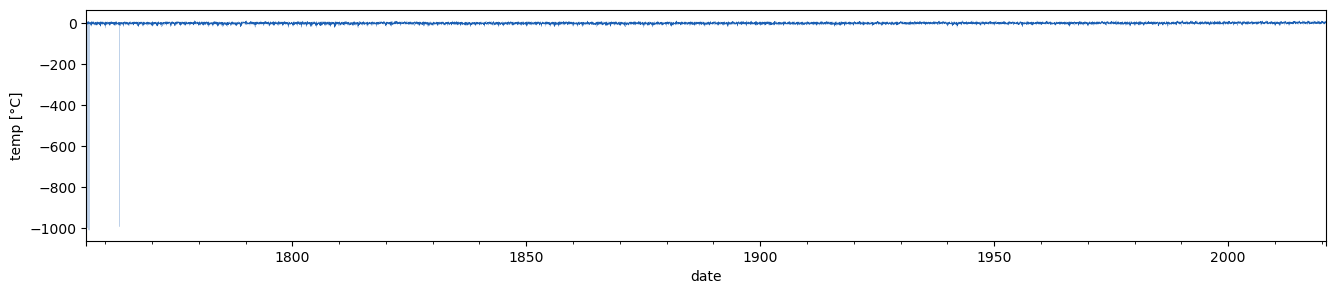

In [41]:
temps_df.plot(x='date',y='deseasoned',figsize=(16,3),linewidth=.1,color='#1B5FB3',legend=False)
plt.ylabel('temp [°C]');

Now we can repeat the analysis that we did for the yearly data!

### Exercise

Do a linear regression on the deseasoned data and store the result as `result_des`. Create a plot with the original data and the regression line.

<details><summary><u>Hint.</u></summary>
<p>
    
Datetime won't work as the x data for the linear regression, so either add a column counting the days or just use the row index `temps_df.index`.
    
</p>
</details>

<details><summary><u>Solution.</u></summary>
<p>
    
```python
result_des = stats.linregress(temps_df.index, temps_df['deseasoned'])
temps_df.deseasoned.plot(figsize=(16,3),linewidth=.1,color='#1B5FB3',legend=False)
x = np.array([min(temps_df.index),max(temps_df.index)])
plt.plot(x,result_des.slope*x+result_des.intercept,linewidth=3,color='#B37D1B')
plt.ylabel('temp [°C]');
plt.xlabel('day index');
print(result_des)
```
    
</p>
</details>

Is this different from the yearly result?

In [ ]:
print('Yearly slope\t=',result_yearly.slope)
print('Daily slope*365\t=',365*result_des.slope)

### statsmodels

In this notebook we looked at some basic statistical test with SciPy. If you are interested in going beyond the scope of this class you can check out the module [statsmodels](https://www.statsmodels.org), it has:
* Many more models and tests.
* Helper functions and some plotting.
* Works with pandas.
* R-style model definition.

## 03 Machine learning -- scikit-learn

[Video.](https://ceu.cloud.panopto.eu/Panopto/Pages/Viewer.aspx?id=f8f63787-ea05-4512-afde-acd300b5bcd9)

Roughly speaking machine learning is statistics only instead of trying to infer properties of the underlying distribution from a sample, the focus is on making predictions.

The main machine learning module of python is [scikit-learn](https://scikit-learn.org), which is built on the usual suspects: NumPy, matplotlib, and SciPy. It has many models and utilities implemented, in the remainder of the class we will look at an example supervised learning problem, just giving you a taste of what is possible.

Let's import the submodules that we will use:

In [42]:
from sklearn import datasets, neighbors, linear_model, model_selection, metrics

### Digits dataset

We will look at a classic example: [the digit dataset](https://archive.ics.uci.edu/ml/datasets/Pen-Based+Recognition+of+Handwritten+Digits). It contains 1797 8x8 grayscale images of hand-written digits from 0 to 9. The 8x8 images are in effect feature vectors with length 64.

The dataset is included in the module, let's take a look-see:

In [43]:
digits = datasets.load_digits()
print(digits.keys())
print("Pixels of the first image:",digits.data[0])
print("Label of the first image:", digits.target[0])
print(digits.data.shape)
print(digits.target.shape)

dict_keys(['data', 'target', 'frame', 'feature_names', 'target_names', 'images', 'DESCR'])
Pixels of the first image: [ 0.  0.  5. 13.  9.  1.  0.  0.  0.  0. 13. 15. 10. 15.  5.  0.  0.  3.
 15.  2.  0. 11.  8.  0.  0.  4. 12.  0.  0.  8.  8.  0.  0.  5.  8.  0.
  0.  9.  8.  0.  0.  4. 11.  0.  1. 12.  7.  0.  0.  2. 14.  5. 10. 12.
  0.  0.  0.  0.  6. 13. 10.  0.  0.  0.]
Label of the first image: 0
(1797, 64)
(1797,)


We can also plot the images:

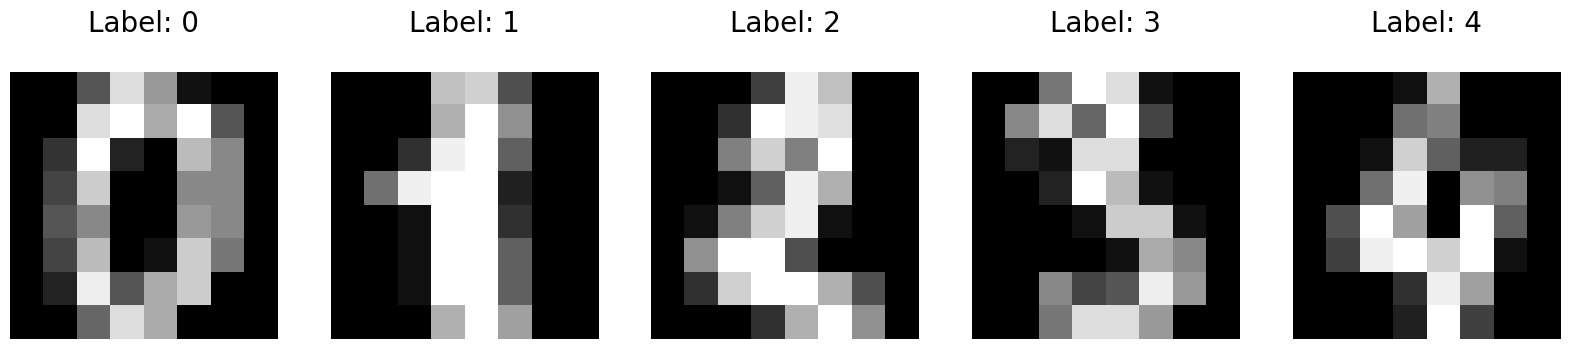

In [44]:
fig,axs=plt.subplots(ncols=5,figsize=(20,4))
for ax, image, label in zip(axs,digits.data[:5], digits.target[:5]):
    ax.imshow(np.reshape(image, (8,8)), cmap=plt.cm.gray) # reshape feature vector to 2 dim image
    ax.set_title('Label: %i\n' % label, fontsize = 20)
    ax.axis('off')

The task is to be able to predict the correct digit from the image. This is a supervised classification problem:
* Classification because the 10 digits are 10 classes.
* Supervised because the images are labeled in the training set.

We split that data into a training set that we use to fit the model, and a test set that we use to gauge how good the model is at predicting labels on new data, in other words how well it generalizes. We'll do a 75%-25% split.

In [45]:
n_samples = len(digits.data)
data_train   = digits.data[:int(.75 * n_samples)]
target_train = digits.target[:int(.75 * n_samples)]

data_test    = digits.data[int(.75 * n_samples):]
target_test  = digits.target[int(.75 * n_samples):]

len(data_train),len(data_test)

(1347, 450)

We can also do this with a helper function which in addition randomly selects the training set:

In [46]:
data_train, data_test, target_train, target_test = model_selection.train_test_split(
    digits.data, digits.target, test_size=0.25, random_state=0)
len(data_train),len(data_test)

(1347, 450)

Where the `random_state` argument sets the seed of the random number for reproducable result.

### Logistic regression

[Video.](https://ceu.cloud.panopto.eu/Panopto/Pages/Viewer.aspx?id=f2d3d786-ac47-4c10-91af-acd300bb9097)

Now we are ready to train a model. Let's try out multinomial [logistic regression](https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression):

In [ ]:
#initialize the model
logistic = linear_model.LogisticRegression()

# fit the model
logistic.fit(data_train,target_train);

In [ ]:
#side note, if you are annoyed by the warnings, uncomment and run:
#import warnings
#warnings.filterwarnings('ignore') 
# downside is you won't see the warning.

Great! How well did we do?

In [ ]:
print(f'LogisticRegression accuracy score: {logistic.score(data_test, target_test):.3f}')

Accuaracy is the fraction of images in the test set that were labelled correctly. Not bad, but there is room for improvement.

To get a more detailed idea about how well we are doing we can calculate the confusion matrix. First we need the predicted labels for the test set:

In [ ]:
predictions = logistic.predict(data_test)
cm = metrics.confusion_matrix(target_test,predictions)

plt.figure(figsize=(9,9))
sns.heatmap(cm, annot=True, fmt="d", linewidths=.5, square = True, cmap = 'Blues_r');
plt.ylabel('Actual label');
plt.xlabel('Predicted label');
plt.title(f'Accuracy Score: {logistic.score(data_test, target_test):.3f}', size = 15);

We can also show some of the mislabelled images:

In [ ]:
#select mislabelled images using a mask
mask = (target_test!= predictions)
mislabelled_data = data_test[mask]
pred = predictions[mask]
actual = target_test[mask]

fig,axs=plt.subplots(ncols=5,figsize=(20,4))
for ax, image, pred_label,act_label in zip(axs,mislabelled_data,pred,actual):
    ax.imshow(np.reshape(image, (8,8)), cmap=plt.cm.gray) # reshape feature vector to 2 dim image
    ax.set_title(f'Predicted: {pred_label},\nactual: {act_label}', fontsize = 20)
    ax.axis('off')

### Exercise

Typically larger training data would lead to better models. Is it true here? Try fitting the data with first 10%, 20%,...,100% of your training set. Calculate the accuracy score for each percentage using the same test set. Plot the accuracy as a function of the training set size! Try selecting differnet training sets by changing the `random_state`.

<details><summary><u>Hint.</u></summary>
<p>
    
```python
Iterate over the precentages using a `for` loop and retrain the model each time. To use 10% of the training data use a slice `data_train[:int(0.1*len(data_train))]`.
```
    
</p>
</details>

<details><summary><u>Solution.</u></summary>
<p>
    
```python
data_train, data_test, target_train, target_test = model_selection.train_test_split(
    digits.data, digits.target, test_size=0.25, random_state=42)

accs = []
for p in np.linspace(.1,1.,10):
    # fit the model
    logistic.fit(data_train[:int(p*len(data_train))],target_train[:int(p*len(data_train))])
    accs.append(logistic.score(data_test, target_test))
    
plt.plot(np.linspace(.1,1.,10), accs,'-o')
plt.xlabel("fraction of training set used")
plt.ylabel('accuracy');
```
    
</p>
</details>

scikit-learn has many models implemented, visualization options and useful tools. It is worth further exploring.